# ECE 285 Homework 3: Denoising Diffusion Probabilistic Model (DDPM) for Histopathology Image Generation

This notebook implements a **Denoising Diffusion Probabilistic Model (DDPM)** from scratch in PyTorch and trains it on the **Histopathology** dataset (`data/Histopathology`, 5,179 images).

Key architectural and training components:
1. **Model & Diffusion Pipeline**: Time-conditioned U-Net with **Adaptive Group Normalization (AdaGN / Scale-Shift)**, zero-initialized residual/output projections, FlashAttention (`scaled_dot_product_attention`), **cosine noise schedule**, **Min-SNR-$\gamma$ loss weighting**, **dynamic thresholding**, and Exponential Moving Average (EMA).
2. **Domain Data Pipeline**: Fast in-memory `64x64` antialias bicubic caching and lossless $D_4$ dihedral group augmentation (random flips + $90^\circ$ rotations) tailored for rotation-invariant H&E histopathology slides.
3. **Training & Loss Tracking**: `bfloat16` mixed-precision acceleration, linear warmup + cosine learning rate schedule, and per-iteration / per-epoch MSE loss logging (`outputs/training_loss_curve.png`).
4. **Quantitative & Qualitative Evaluation**: Inception Score (IS) and Fréchet Inception Distance (FID) via **PyTorch-Ignite**, alongside generated sample grids and reverse denoising trajectories.

## 1. Environment Setup & Device Configuration

In [2]:
import os
import math
import json
import copy
import time
import random
from dataclasses import dataclass, asdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import PIL.Image as Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.transforms as transforms
import torchvision.utils as vutils

import ignite
from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

# Enable TF32 Tensor Cores on Ampere/Ada/Blackwell CUDA GPUs
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")

print(f"PyTorch     : {torch.__version__}")
print(f"Ignite      : {ignite.__version__}")


def get_device() -> torch.device:
    if torch.cuda.is_available():
        dev = torch.device("cuda")
        print(f"Active Device: {dev} ({torch.cuda.get_device_name(0)})")
        print(f"BF16 Support : {torch.cuda.is_bf16_supported()}")
    elif torch.backends.mps.is_available():
        dev = torch.device("mps")
        print(f"Active Device: {dev}")
    else:
        dev = torch.device("cpu")
        print(f"Active Device: {dev}")
    return dev


def set_seed(seed: int = 42, device: torch.device | None = None) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if device is not None and device.type == "mps":
        torch.mps.manual_seed(seed)
    elif torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


device = get_device()

d:\Anaconda\envs\ml-pip\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch     : 2.10.0+cu130
Ignite      : 0.5.5
Active Device: cuda (NVIDIA GeForce RTX 5070 Ti)
BF16 Support : True


## 2. Hyperparameter Configuration

All hyperparameters for data processing, the AdaGN U-Net backbone, the cosine DDPM schedule with Min-SNR-$\gamma$ loss weighting, optimization, and PyTorch-Ignite FID/IS evaluation are centralized below.

In [3]:
@dataclass
class Config:
    # Paths
    data_dir: str = "./data/Histopathology"
    output_dir: str = "./outputs"
    checkpoint_dir: str = "./checkpoints"

    # Reproducibility
    seed: int = 42

    # Data
    image_size: int = 64
    in_channels: int = 3
    batch_size: int = 32          # 161 steps/epoch -> 64,400 gradient updates over 400 epochs
    num_workers: int = 0          # 0 is fastest & safest in Jupyter when cache_in_ram=True
    cache_in_ram: bool = True     # Preload resized 64x64 uint8 tensors (~64 MB) to eliminate disk I/O

    # U-Net Architecture
    base_channels: int = 64
    channel_mults: tuple = (1, 2, 4, 4)
    num_res_blocks: int = 2
    attn_resolutions: tuple = (16, 8)
    dropout: float = 0.05
    num_heads: int = 4
    scale_shift_norm: bool = True # AdaGN (FiLM) time modulation

    # Diffusion Schedule & Loss (DDPM)
    timesteps: int = 1000
    beta_schedule: str = "cosine" # "cosine" preserves structure much better than "linear" at 64x64
    beta_start: float = 1e-4
    beta_end: float = 0.02
    min_snr_gamma: float = 5.0    # Min-SNR-gamma loss weighting (Hang et al., ICCV 2023)
    dynamic_threshold: bool = True
    dynamic_threshold_p: float = 0.995

    # Optimization & Mixed Precision
    epochs: int = 400
    lr: float = 2e-4
    min_lr: float = 2e-5
    warmup_steps: int = 1000
    weight_decay: float = 1e-4
    grad_clip: float = 1.0
    ema_decay: float = 0.9995
    use_amp: bool = True          # Automatically uses bfloat16 on supported CUDA GPUs

    # Logging, Sampling & Evaluation
    log_interval: int = 10        # Print epoch summary every N epochs
    sample_interval: int = 25     # Save intermediate sample grid every N epochs
    preview_use_ddim: bool = True # Fast 100-step DDIM for intermediate epoch previews
    eval_batch_size: int = 64
    eval_num_samples: int = 2048  # Randomly sampled real/fake pairs for reliable FID & IS
    eval_use_ddim: bool = False   # Full 1000-step DDPM for final quantitative evaluation
    ddim_steps: int = 100
    ddim_eta: float = 0.0


cfg = Config()
set_seed(cfg.seed, device)

Path(cfg.output_dir).mkdir(parents=True, exist_ok=True)
Path(cfg.checkpoint_dir).mkdir(parents=True, exist_ok=True)

print("=== Hyperparameter Settings ===")
for k, v in asdict(cfg).items():
    print(f"{k:<22s}: {v}")

with open(Path(cfg.output_dir) / "hyperparameters.json", "w") as f:
    json.dump(asdict(cfg), f, indent=2)

=== Hyperparameter Settings ===
data_dir              : ./data/Histopathology
output_dir            : ./outputs
checkpoint_dir        : ./checkpoints
seed                  : 42
image_size            : 64
in_channels           : 3
batch_size            : 32
num_workers           : 0
cache_in_ram          : True
base_channels         : 64
channel_mults         : (1, 2, 4, 4)
num_res_blocks        : 2
attn_resolutions      : (16, 8)
dropout               : 0.05
num_heads             : 4
scale_shift_norm      : True
timesteps             : 1000
beta_schedule         : cosine
beta_start            : 0.0001
beta_end              : 0.02
min_snr_gamma         : 5.0
dynamic_threshold     : True
dynamic_threshold_p   : 0.995
epochs                : 400
lr                    : 0.0002
min_lr                : 2e-05
warmup_steps          : 1000
weight_decay          : 0.0001
grad_clip             : 1.0
ema_decay             : 0.9995
use_amp               : True
log_interval          : 10
sample_inte

## 3. Dataset Loading, In-Memory Caching & $D_4$ Augmentation (`data/Histopathology`)

The `data/Histopathology` folder contains 5,179 RGB PNG histopathology patches (`256 x 256`).
- We resize images to `64 x 64` with `PIL.Image.BICUBIC` (antialiased, crisp nuclear boundaries) and optionally cache the compact `uint8` tensor (`~64 MB` total) in RAM to eliminate disk decoding bottlenecks.
- Because microscopy slides have no canonical orientation, training applies full **$D_4$ dihedral group augmentation** (random horizontal flip + random $0^\circ/90^\circ/180^\circ/270^\circ$ exact tensor rotation, yielding $8\times$ lossless geometric diversity) before scaling to `[-1, 1]`.
- For evaluation, `eval_dataset` draws a seeded random subset of `eval_num_samples` images rather than slicing sorted filenames.

Cached tensor in RAM        : (5179, 3, 64, 64) (60.7 MB)
Total Histopathology images : 5179
Training batches / epoch    : 161 (total steps = 64,400)
Evaluation images (FID/IS)  : 2048


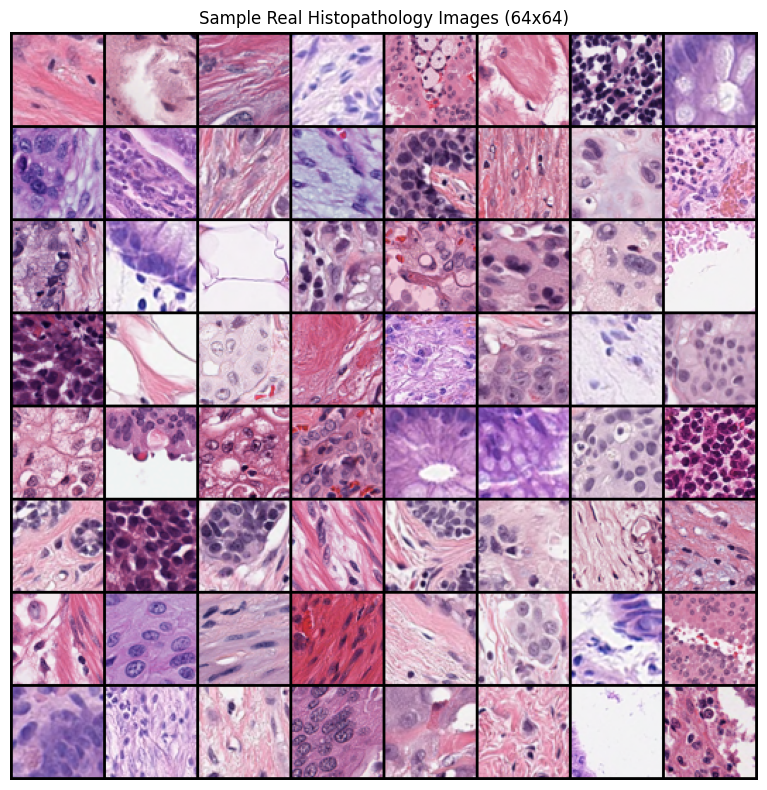

In [4]:
class HistopathologyDataset(Dataset):
    def __init__(
        self,
        root_dir: str,
        image_size: int = 64,
        augment: bool = False,
        cache_images: torch.Tensor | None = None,
        cache_in_ram: bool = True,
        cache_file: Path | None = None,
    ):
        self.root_dir = Path(root_dir)
        self.image_size = image_size
        self.augment = augment
        self.image_paths = sorted(
            [p for p in self.root_dir.iterdir() if p.is_file() and not p.name.startswith(".") and p.suffix.lower() == ".png"]
        )
        if len(self.image_paths) == 0:
            raise RuntimeError(f"No PNG images found in {self.root_dir.resolve()}")

        if cache_images is not None:
            self.cached_uint8 = cache_images
        elif cache_in_ram:
            if cache_file is not None and cache_file.is_file():
                self.cached_uint8 = torch.load(cache_file, map_location="cpu", weights_only=True)
            else:
                def _decode_one(p: Path) -> torch.Tensor:
                    with Image.open(p) as img:
                        img = img.convert("RGB").resize((image_size, image_size), Image.BICUBIC)
                        arr = np.array(img, dtype=np.uint8, copy=True)
                        return torch.from_numpy(arr).permute(2, 0, 1).contiguous()

                with ThreadPoolExecutor(max_workers=min(8, os.cpu_count() or 4)) as pool:
                    imgs = list(tqdm(
                        pool.map(_decode_one, self.image_paths),
                        total=len(self.image_paths),
                        desc=f"Caching {image_size}x{image_size} dataset in RAM",
                        leave=False,
                    ))
                self.cached_uint8 = torch.stack(imgs, dim=0)  # (N, 3, H, W) uint8
                if cache_file is not None:
                    cache_file.parent.mkdir(parents=True, exist_ok=True)
                    torch.save(self.cached_uint8, cache_file)
        else:
            self.cached_uint8 = None

    def __len__(self) -> int:
        return len(self.image_paths)

    def _load_uint8(self, idx: int) -> torch.Tensor:
        if self.cached_uint8 is not None:
            return self.cached_uint8[idx]
        with Image.open(self.image_paths[idx]) as img:
            img = img.convert("RGB").resize((self.image_size, self.image_size), Image.BICUBIC)
            arr = np.array(img, dtype=np.uint8, copy=True)
            return torch.from_numpy(arr).permute(2, 0, 1).contiguous()

    def __getitem__(self, idx: int) -> torch.Tensor:
        x = self._load_uint8(idx)
        if self.augment:
            # Full D4 symmetry group: random horizontal flip + random 90-degree rotation
            if torch.rand(()) < 0.5:
                x = torch.flip(x, dims=[2])
            k = int(torch.randint(0, 4, ()).item())
            if k > 0:
                x = torch.rot90(x, k=k, dims=[1, 2])
        return x.to(dtype=torch.float32).div_(127.5).sub_(1.0)  # [-1, 1]


cache_path = Path(cfg.checkpoint_dir) / f"histopathology_uint8_{cfg.image_size}x{cfg.image_size}.pt"

train_dataset = HistopathologyDataset(
    cfg.data_dir,
    image_size=cfg.image_size,
    augment=True,
    cache_in_ram=cfg.cache_in_ram,
    cache_file=cache_path,
)
eval_full_dataset = HistopathologyDataset(
    cfg.data_dir,
    image_size=cfg.image_size,
    augment=False,
    cache_images=train_dataset.cached_uint8,
    cache_in_ram=cfg.cache_in_ram,
)

num_eval = min(cfg.eval_num_samples, len(eval_full_dataset))
eval_perm_gen = torch.Generator().manual_seed(cfg.seed)
eval_indices = torch.randperm(len(eval_full_dataset), generator=eval_perm_gen)[:num_eval].tolist()
eval_dataset = Subset(eval_full_dataset, eval_indices)

use_pin_memory = device.type == "cuda"

train_dataloader = DataLoader(
    train_dataset,
    batch_size=cfg.batch_size,
    shuffle=True,
    num_workers=cfg.num_workers,
    pin_memory=use_pin_memory,
    drop_last=True,
)

eval_dataloader = DataLoader(
    eval_dataset,
    batch_size=cfg.eval_batch_size,
    shuffle=False,
    num_workers=cfg.num_workers,
    pin_memory=use_pin_memory,
    drop_last=False,
)

if train_dataset.cached_uint8 is not None:
    cache_mb = train_dataset.cached_uint8.numel() / (1024 ** 2)
    print(f"Cached tensor in RAM        : {tuple(train_dataset.cached_uint8.shape)} ({cache_mb:.1f} MB)")
print(f"Total Histopathology images : {len(train_dataset)}")
print(f"Training batches / epoch    : {len(train_dataloader)} (total steps = {len(train_dataloader) * cfg.epochs:,})")
print(f"Evaluation images (FID/IS)  : {len(eval_dataset)}")

# Visualize a batch of real training images
vis_loader = DataLoader(eval_dataset, batch_size=64, shuffle=False)
real_batch = next(iter(vis_loader))
plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Sample Real Histopathology Images (64x64)")
grid = vutils.make_grid(real_batch[:64], nrow=8, padding=2, normalize=True, value_range=(-1, 1))
plt.imshow(np.transpose(grid.cpu().numpy(), (1, 2, 0)))
plt.tight_layout()
plt.savefig(Path(cfg.output_dir) / "real_samples.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Denoising U-Net Architecture (AdaGN & Zero-Initialization)

We implement a time-conditioned U-Net (`UNet`) following Dhariwal & Nichol (*ADM*, 2021):
- Sinusoidal timestep embeddings projected through a two-layer SiLU MLP
- Residual blocks (`ResBlock`) with `GroupNorm`, **Adaptive GroupNorm (`scale * (1 + norm(h)) + shift`)** time-conditioning, dropout, and zero-initialized second convolutions
- Multi-head self-attention (`SelfAttention2d`) accelerated via `F.scaled_dot_product_attention` at `16x16` and `8x8` resolutions with zero-initialized output projections
- Zero-initialized final output convolution so initial noise predictions start smoothly around zero

In [5]:
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, time: torch.Tensor) -> torch.Tensor:
        dev = time.device
        half_dim = self.dim // 2
        emb_scale = math.log(10000.0) / max(half_dim - 1, 1)
        freqs = torch.exp(torch.arange(half_dim, device=dev, dtype=torch.float32) * -emb_scale)
        args = time.float().unsqueeze(1) * freqs.unsqueeze(0)
        emb = torch.cat((args.sin(), args.cos()), dim=-1)
        if self.dim % 2 == 1:
            emb = F.pad(emb, (0, 1))
        return emb


def _num_groups(channels: int, max_groups: int = 32) -> int:
    for g in range(min(max_groups, channels), 0, -1):
        if channels % g == 0:
            return g
    return 1


class ResBlock(nn.Module):
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        time_dim: int,
        dropout: float = 0.05,
        scale_shift_norm: bool = True,
    ):
        super().__init__()
        self.scale_shift_norm = scale_shift_norm
        self.norm1 = nn.GroupNorm(_num_groups(in_channels), in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)

        self.time_mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_dim, out_channels * 2 if scale_shift_norm else out_channels),
        )

        self.norm2 = nn.GroupNorm(_num_groups(out_channels), out_channels)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)
        nn.init.zeros_(self.conv2.weight)
        nn.init.zeros_(self.conv2.bias)

        self.shortcut = (
            nn.Conv2d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x: torch.Tensor, t_emb: torch.Tensor) -> torch.Tensor:
        h = self.conv1(F.silu(self.norm1(x)))
        t_out = self.time_mlp(t_emb)[:, :, None, None]
        if self.scale_shift_norm:
            scale, shift = t_out.chunk(2, dim=1)
            h = self.norm2(h) * (1.0 + scale) + shift
            h = self.conv2(self.dropout(F.silu(h)))
        else:
            h = h + t_out
            h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.shortcut(x)


class SelfAttention2d(nn.Module):
    def __init__(self, channels: int, num_heads: int = 4):
        super().__init__()
        assert channels % num_heads == 0, f"channels ({channels}) must be divisible by num_heads ({num_heads})"
        self.num_heads = num_heads
        self.head_dim = channels // num_heads
        self.norm = nn.GroupNorm(_num_groups(channels), channels)
        self.qkv = nn.Conv2d(channels, channels * 3, kernel_size=1)
        self.proj = nn.Conv2d(channels, channels, kernel_size=1)
        nn.init.zeros_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, c, h, w = x.shape
        qkv = self.qkv(self.norm(x))
        q, k, v = qkv.chunk(3, dim=1)

        # Shape (B, heads, HW, head_dim) for Flash / SDPA kernel
        q = q.view(b, self.num_heads, self.head_dim, h * w).transpose(2, 3)
        k = k.view(b, self.num_heads, self.head_dim, h * w).transpose(2, 3)
        v = v.view(b, self.num_heads, self.head_dim, h * w).transpose(2, 3)

        out = F.scaled_dot_product_attention(q, k, v)
        out = out.transpose(2, 3).contiguous().view(b, c, h, w)
        return x + self.proj(out)


class Downsample(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=3, stride=2, padding=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=3, padding=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = F.interpolate(x, scale_factor=2.0, mode="nearest")
        return self.conv(x)


class UNet(nn.Module):
    def __init__(
        self,
        in_channels: int = 3,
        base_channels: int = 64,
        channel_mults: tuple = (1, 2, 4, 4),
        num_res_blocks: int = 2,
        image_size: int = 64,
        attn_resolutions: tuple = (16, 8),
        dropout: float = 0.05,
        num_heads: int = 4,
        scale_shift_norm: bool = True,
    ):
        super().__init__()
        time_dim = base_channels * 4
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(base_channels),
            nn.Linear(base_channels, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )

        self.init_conv = nn.Conv2d(in_channels, base_channels, kernel_size=3, padding=1)

        # Downsampling path
        self.down_blocks = nn.ModuleList()
        ch = base_channels
        curr_res = image_size
        skip_channels = [ch]
        num_levels = len(channel_mults)

        for level, mult in enumerate(channel_mults):
            out_ch = base_channels * mult
            for _ in range(num_res_blocks):
                layers = nn.ModuleList([
                    ResBlock(ch, out_ch, time_dim, dropout=dropout, scale_shift_norm=scale_shift_norm)
                ])
                if curr_res in attn_resolutions:
                    layers.append(SelfAttention2d(out_ch, num_heads=num_heads))
                self.down_blocks.append(layers)
                ch = out_ch
                skip_channels.append(ch)
            if level != num_levels - 1:
                self.down_blocks.append(nn.ModuleList([Downsample(ch)]))
                skip_channels.append(ch)
                curr_res //= 2

        # Bottleneck
        self.mid_block1 = ResBlock(ch, ch, time_dim, dropout=dropout, scale_shift_norm=scale_shift_norm)
        self.mid_attn = SelfAttention2d(ch, num_heads=num_heads)
        self.mid_block2 = ResBlock(ch, ch, time_dim, dropout=dropout, scale_shift_norm=scale_shift_norm)

        # Upsampling path
        self.up_blocks = nn.ModuleList()
        for level, mult in reversed(list(enumerate(channel_mults))):
            out_ch = base_channels * mult
            for i in range(num_res_blocks + 1):
                skip_ch = skip_channels.pop()
                layers = nn.ModuleList([
                    ResBlock(ch + skip_ch, out_ch, time_dim, dropout=dropout, scale_shift_norm=scale_shift_norm)
                ])
                if curr_res in attn_resolutions:
                    layers.append(SelfAttention2d(out_ch, num_heads=num_heads))
                if level != 0 and i == num_res_blocks:
                    layers.append(Upsample(out_ch))
                    curr_res *= 2
                self.up_blocks.append(layers)
                ch = out_ch

        self.out_norm = nn.GroupNorm(_num_groups(ch), ch)
        self.out_conv = nn.Conv2d(ch, in_channels, kernel_size=3, padding=1)
        nn.init.zeros_(self.out_conv.weight)
        nn.init.zeros_(self.out_conv.bias)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        t_emb = self.time_mlp(t)
        h = self.init_conv(x)
        hs = [h]

        for block in self.down_blocks:
            if isinstance(block[0], Downsample):
                h = block[0](h)
            else:
                h = block[0](h, t_emb)
                if len(block) > 1:
                    h = block[1](h)
            hs.append(h)

        h = self.mid_block1(h, t_emb)
        h = self.mid_attn(h)
        h = self.mid_block2(h, t_emb)

        for block in self.up_blocks:
            skip = hs.pop()
            h = torch.cat([h, skip], dim=1)
            h = block[0](h, t_emb)
            for layer in block[1:]:
                h = layer(h)

        return self.out_conv(F.silu(self.out_norm(h)))

## 5. DDPM Forward/Reverse Process, Min-SNR-$\gamma$ Weighting & EMA

We implement `GaussianDiffusion` with:
- **Cosine noise schedule** (Nichol & Dhariwal, 2021) with $\beta_t \le 0.999$, preventing premature signal destruction on `64 x 64` patches.
- **Min-SNR-$\gamma$ loss weighting** (Hang et al., 2023): weights per-timestep MSE by $\frac{\min(\text{SNR}(t), \gamma)}{\text{SNR}(t)}$ ($\gamma = 5.0$), balancing gradient magnitudes across noise levels and eliminating global H&E color shift.
- **Dynamic thresholding** (Saharia et al., 2022) on $\hat{x}_0$ predictions to prevent RGB channel saturation artifacts.
- `bfloat16` autocast inside U-Net forward passes while keeping all diffusion algebra in exact `float32`.

In [6]:
def linear_beta_schedule(timesteps: int, beta_start: float = 1e-4, beta_end: float = 0.02) -> torch.Tensor:
    return torch.linspace(beta_start, beta_end, timesteps, dtype=torch.float32)


def cosine_beta_schedule(timesteps: int, s: float = 0.008) -> torch.Tensor:
    steps = timesteps + 1
    x = torch.linspace(0, timesteps, steps, dtype=torch.float64)
    alphas_cumprod = torch.cos(((x / timesteps) + s) / (1.0 + s) * math.pi * 0.5) ** 2
    alphas_cumprod = alphas_cumprod / alphas_cumprod[0]
    betas = 1.0 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
    return torch.clamp(betas, 0.0001, 0.999).float()


def extract(a: torch.Tensor, t: torch.Tensor, x_shape: tuple) -> torch.Tensor:
    batch_size = t.shape[0]
    out = a.gather(-1, t)
    return out.reshape(batch_size, *((1,) * (len(x_shape) - 1)))


class GaussianDiffusion(nn.Module):
    def __init__(
        self,
        model: nn.Module,
        image_size: int = 64,
        in_channels: int = 3,
        timesteps: int = 1000,
        beta_schedule: str = "cosine",
        beta_start: float = 1e-4,
        beta_end: float = 0.02,
        min_snr_gamma: float = 5.0,
        dynamic_threshold: bool = True,
        dynamic_threshold_p: float = 0.995,
        use_amp: bool = True,
    ):
        super().__init__()
        self.model = model
        self.image_size = image_size
        self.in_channels = in_channels
        self.timesteps = timesteps
        self.min_snr_gamma = min_snr_gamma
        self.dynamic_threshold = dynamic_threshold
        self.dynamic_threshold_p = dynamic_threshold_p
        self.use_amp = use_amp

        if beta_schedule == "linear":
            betas = linear_beta_schedule(timesteps, beta_start, beta_end)
        elif beta_schedule == "cosine":
            betas = cosine_beta_schedule(timesteps)
        else:
            raise ValueError(f"Unknown beta_schedule: {beta_schedule}")

        alphas = 1.0 - betas
        alphas_cumprod = torch.cumprod(alphas, dim=0)
        alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value=1.0)

        self.register_buffer("betas", betas)
        self.register_buffer("alphas", alphas)
        self.register_buffer("alphas_cumprod", alphas_cumprod)
        self.register_buffer("alphas_cumprod_prev", alphas_cumprod_prev)

        # Forward process q(x_t | x_0)
        self.register_buffer("sqrt_alphas_cumprod", torch.sqrt(alphas_cumprod))
        self.register_buffer("sqrt_one_minus_alphas_cumprod", torch.sqrt(1.0 - alphas_cumprod))

        # Reverse process q(x_{t-1} | x_t, x_0)
        self.register_buffer("sqrt_recip_alphas_cumprod", torch.sqrt(1.0 / alphas_cumprod))
        self.register_buffer("sqrt_recipm1_alphas_cumprod", torch.sqrt(1.0 / alphas_cumprod - 1.0))

        posterior_variance = betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)
        self.register_buffer("posterior_variance", posterior_variance)
        self.register_buffer("posterior_log_variance_clipped", torch.log(torch.clamp(posterior_variance, min=1e-20)))
        self.register_buffer(
            "posterior_mean_coef1",
            betas * torch.sqrt(alphas_cumprod_prev) / (1.0 - alphas_cumprod),
        )
        self.register_buffer(
            "posterior_mean_coef2",
            (1.0 - alphas_cumprod_prev) * torch.sqrt(alphas) / (1.0 - alphas_cumprod),
        )

        # Min-SNR-gamma weights: min(SNR(t), gamma) / SNR(t)
        snr = alphas_cumprod / torch.clamp(1.0 - alphas_cumprod, min=1e-8)
        self.register_buffer("snr", snr)
        if min_snr_gamma is not None and min_snr_gamma > 0:
            loss_weights = torch.clamp(snr, max=min_snr_gamma) / snr
        else:
            loss_weights = torch.ones_like(snr)
        self.register_buffer("loss_weights", loss_weights)

    def _predict_noise(self, x_t: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        amp_enabled = self.use_amp and x_t.device.type == "cuda" and torch.cuda.is_bf16_supported()
        with torch.amp.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=amp_enabled):
            pred = self.model(x_t, t)
        return pred.float()

    def _threshold_x_start(self, x_start: torch.Tensor) -> torch.Tensor:
        if not self.dynamic_threshold:
            return torch.clamp(x_start, -1.0, 1.0)
        b = x_start.shape[0]
        s = torch.quantile(x_start.abs().reshape(b, -1), self.dynamic_threshold_p, dim=1)
        s = torch.clamp(s, min=1.0).view(b, 1, 1, 1)
        return torch.clamp(x_start, -s, s) / s

    def q_sample(self, x_start: torch.Tensor, t: torch.Tensor, noise: torch.Tensor | None = None) -> torch.Tensor:
        if noise is None:
            noise = torch.randn_like(x_start)
        return (
            extract(self.sqrt_alphas_cumprod, t, x_start.shape) * x_start
            + extract(self.sqrt_one_minus_alphas_cumprod, t, x_start.shape) * noise
        )

    def training_loss(self, x_start: torch.Tensor, return_raw_mse: bool = False):
        b = x_start.shape[0]
        t = torch.randint(0, self.timesteps, (b,), device=x_start.device, dtype=torch.long)
        noise = torch.randn_like(x_start)
        x_noisy = self.q_sample(x_start, t, noise=noise)
        pred_noise = self._predict_noise(x_noisy, t)

        mse_per_sample = F.mse_loss(pred_noise, noise, reduction="none").mean(dim=(1, 2, 3))
        weights = self.loss_weights.gather(-1, t)
        weighted_loss = (mse_per_sample * weights).mean()
        if return_raw_mse:
            return weighted_loss, mse_per_sample.mean().detach()
        return weighted_loss

    def predict_start_from_noise(self, x_t: torch.Tensor, t: torch.Tensor, noise: torch.Tensor) -> torch.Tensor:
        return (
            extract(self.sqrt_recip_alphas_cumprod, t, x_t.shape) * x_t
            - extract(self.sqrt_recipm1_alphas_cumprod, t, x_t.shape) * noise
        )

    @torch.no_grad()
    def p_sample(self, x_t: torch.Tensor, t_idx: int) -> torch.Tensor:
        b = x_t.shape[0]
        t = torch.full((b,), t_idx, device=x_t.device, dtype=torch.long)
        pred_noise = self._predict_noise(x_t, t)
        x_start = self.predict_start_from_noise(x_t, t, pred_noise)
        x_start = self._threshold_x_start(x_start)

        model_mean = (
            extract(self.posterior_mean_coef1, t, x_t.shape) * x_start
            + extract(self.posterior_mean_coef2, t, x_t.shape) * x_t
        )
        if t_idx == 0:
            return model_mean
        posterior_var = extract(self.posterior_variance, t, x_t.shape)
        noise = torch.randn_like(x_t)
        return model_mean + torch.sqrt(posterior_var) * noise

    @torch.no_grad()
    def sample(
        self,
        batch_size: int,
        noise: torch.Tensor | None = None,
        show_progress: bool = False,
        return_trajectory: bool = False,
        trajectory_steps: tuple = (999, 800, 600, 400, 200, 100, 50, 0),
    ):
        dev = self.betas.device
        x = noise.to(dev) if noise is not None else torch.randn(
            batch_size, self.in_channels, self.image_size, self.image_size, device=dev
        )
        traj = {}
        iterator = reversed(range(self.timesteps))
        if show_progress:
            iterator = tqdm(list(iterator), desc="DDPM Sampling", leave=False)

        for t_idx in iterator:
            x = self.p_sample(x, t_idx)
            if return_trajectory and t_idx in trajectory_steps:
                traj[t_idx] = torch.clamp(x, -1.0, 1.0).detach().cpu()

        x = torch.clamp(x, -1.0, 1.0)
        if return_trajectory:
            return x, traj
        return x

    @torch.no_grad()
    def sample_ddim(
        self,
        batch_size: int,
        ddim_steps: int = 100,
        eta: float = 0.0,
        noise: torch.Tensor | None = None,
        show_progress: bool = False,
    ) -> torch.Tensor:
        dev = self.betas.device
        x = noise.to(dev) if noise is not None else torch.randn(
            batch_size, self.in_channels, self.image_size, self.image_size, device=dev
        )
        step_indices = torch.linspace(0, self.timesteps - 1, ddim_steps, dtype=torch.long).tolist()
        step_indices = list(reversed(step_indices))

        iterator = range(len(step_indices))
        if show_progress:
            iterator = tqdm(list(iterator), desc=f"DDIM ({ddim_steps} steps)", leave=False)

        for i in iterator:
            t_cur = step_indices[i]
            t_prev = step_indices[i + 1] if i + 1 < len(step_indices) else -1

            t_tensor = torch.full((x.shape[0],), t_cur, device=dev, dtype=torch.long)
            pred_noise = self._predict_noise(x, t_tensor)

            alpha_bar_t = self.alphas_cumprod[t_cur]
            alpha_bar_prev = self.alphas_cumprod[t_prev] if t_prev >= 0 else torch.tensor(1.0, device=dev)

            x_0_pred = (x - torch.sqrt(1.0 - alpha_bar_t) * pred_noise) / torch.sqrt(alpha_bar_t)
            x_0_pred = self._threshold_x_start(x_0_pred)

            sigma = (
                eta
                * torch.sqrt((1.0 - alpha_bar_prev) / (1.0 - alpha_bar_t))
                * torch.sqrt(1.0 - alpha_bar_t / alpha_bar_prev)
            )
            dir_xt = torch.sqrt(torch.clamp(1.0 - alpha_bar_prev - sigma ** 2, min=0.0)) * pred_noise
            z = torch.randn_like(x) if t_prev >= 0 and eta > 0 else 0.0
            x = torch.sqrt(alpha_bar_prev) * x_0_pred + dir_xt + sigma * z

        return torch.clamp(x, -1.0, 1.0)


class EMA:
    def __init__(self, model: nn.Module, decay: float = 0.9995):
        self.decay = decay
        self.ema_model = copy.deepcopy(model).eval()
        for p in self.ema_model.parameters():
            p.requires_grad_(False)
        self._ema_params = list(self.ema_model.parameters())

    @torch.no_grad()
    def update(self, model: nn.Module, step: int | None = None) -> None:
        decay = self.decay
        if step is not None:
            decay = min(self.decay, (1.0 + step) / (10.0 + step))
        torch._foreach_lerp_(self._ema_params, list(model.parameters()), 1.0 - decay)
        for ema_b, b in zip(self.ema_model.buffers(), model.buffers()):
            ema_b.copy_(b)

## 6. Model Initialization & Training

We optimize the U-Net with `AdamW` (applying weight decay only to weight matrices, excluding `GroupNorm` scale/bias and conv biases), a per-iteration **Linear Warmup (`1,000` steps) + Cosine Decay (`2e-4 -> 2e-5`)** learning rate schedule, gradient norm clipping (`1.0`), and EMA (`decay = 0.9995`).

In [8]:
use_channels_last = device.type == "cuda"
unet = UNet(
    in_channels=cfg.in_channels,
    base_channels=cfg.base_channels,
    channel_mults=cfg.channel_mults,
    num_res_blocks=cfg.num_res_blocks,
    image_size=cfg.image_size,
    attn_resolutions=cfg.attn_resolutions,
    dropout=cfg.dropout,
    num_heads=cfg.num_heads,
    scale_shift_norm=cfg.scale_shift_norm,
).to(device)
if use_channels_last:
    unet = unet.to(memory_format=torch.channels_last)

diffusion = GaussianDiffusion(
    model=unet,
    image_size=cfg.image_size,
    in_channels=cfg.in_channels,
    timesteps=cfg.timesteps,
    beta_schedule=cfg.beta_schedule,
    beta_start=cfg.beta_start,
    beta_end=cfg.beta_end,
    min_snr_gamma=cfg.min_snr_gamma,
    dynamic_threshold=cfg.dynamic_threshold,
    dynamic_threshold_p=cfg.dynamic_threshold_p,
    use_amp=cfg.use_amp,
).to(device)

num_params = sum(p.numel() for p in unet.parameters())
print(f"U-Net Trainable Parameters: {num_params:,} ({num_params / 1e6:.2f} M)")

ema = EMA(diffusion, decay=cfg.ema_decay)

decay_params = [p for p in unet.parameters() if p.requires_grad and p.ndim >= 2]
nodecay_params = [p for p in unet.parameters() if p.requires_grad and p.ndim < 2]
optimizer = torch.optim.AdamW(
    [
        {"params": decay_params, "weight_decay": cfg.weight_decay},
        {"params": nodecay_params, "weight_decay": 0.0},
    ],
    lr=cfg.lr,
    betas=(0.9, 0.999),
    fused=(device.type == "cuda"),
)

total_steps = cfg.epochs * len(train_dataloader)
min_lr_ratio = cfg.min_lr / cfg.lr


def lr_lambda(current_step: int) -> float:
    if current_step < cfg.warmup_steps:
        return float(current_step + 1) / float(max(1, cfg.warmup_steps))
    progress = float(current_step - cfg.warmup_steps) / float(max(1, total_steps - cfg.warmup_steps))
    progress = min(max(progress, 0.0), 1.0)
    cosine = 0.5 * (1.0 + math.cos(math.pi * progress))
    return min_lr_ratio + (1.0 - min_lr_ratio) * cosine


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)

fixed_noise = torch.randn(64, cfg.in_channels, cfg.image_size, cfg.image_size, device=device)

step_losses = []          # Min-SNR weighted loss
step_raw_mse_losses = []  # Unweighted raw MSE loss
epoch_losses = []         # Epoch avg Min-SNR weighted loss
epoch_raw_mse_losses = [] # Epoch avg unweighted MSE loss
global_step = 0
start_time = time.time()

epoch_pbar = tqdm(range(1, cfg.epochs + 1), desc="Training Epochs")
all_model_params = list(diffusion.parameters())

for epoch in epoch_pbar:
    diffusion.train()
    epoch_step_w = []
    epoch_step_raw = []

    for real_imgs in train_dataloader:
        if use_channels_last:
            real_imgs = real_imgs.to(device, memory_format=torch.channels_last, non_blocking=True)
        else:
            real_imgs = real_imgs.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        loss, raw_mse = diffusion.training_loss(real_imgs, return_raw_mse=True)
        loss.backward()
        if cfg.grad_clip > 0:
            nn.utils.clip_grad_norm_(all_model_params, cfg.grad_clip, foreach=(device.type == "cuda"))
        optimizer.step()
        scheduler.step()

        global_step += 1
        ema.update(diffusion, step=global_step)

        epoch_step_w.append(loss.detach())
        epoch_step_raw.append(raw_mse.detach())

    # Single host-device sync per epoch instead of 322 per-step .item() syncs
    w_vals = torch.stack(epoch_step_w).cpu().tolist()
    raw_vals = torch.stack(epoch_step_raw).cpu().tolist()
    step_losses.extend(w_vals)
    step_raw_mse_losses.extend(raw_vals)

    avg_epoch_loss = sum(w_vals) / len(w_vals)
    avg_epoch_raw_mse = sum(raw_vals) / len(raw_vals)
    epoch_losses.append(avg_epoch_loss)
    epoch_raw_mse_losses.append(avg_epoch_raw_mse)

    cur_lr = optimizer.param_groups[0]["lr"]
    elapsed = time.time() - start_time
    epoch_pbar.set_postfix({
        "w_loss": f"{avg_epoch_loss:.4f}",
        "mse": f"{avg_epoch_raw_mse:.4f}",
        "lr": f"{cur_lr:.2e}",
    })

    if epoch == 1 or epoch % cfg.log_interval == 0 or epoch == cfg.epochs:
        print(
            f"Epoch [{epoch:03d}/{cfg.epochs:03d}] | "
            f"Min-SNR Loss: {avg_epoch_loss:.5f} | Raw MSE: {avg_epoch_raw_mse:.5f} | "
            f"LR: {cur_lr:.2e} | Elapsed: {elapsed / 60:.1f} min"
        )

    # Save sample preview and checkpoint periodically
    if epoch % cfg.sample_interval == 0 or epoch == cfg.epochs:
        ema.ema_model.eval()
        with torch.no_grad():
            if cfg.preview_use_ddim and epoch != cfg.epochs:
                samples = ema.ema_model.sample_ddim(
                    batch_size=64, ddim_steps=cfg.ddim_steps, eta=cfg.ddim_eta, noise=fixed_noise
                )
            elif cfg.eval_use_ddim:
                samples = ema.ema_model.sample_ddim(
                    batch_size=64, ddim_steps=cfg.ddim_steps, eta=cfg.ddim_eta, noise=fixed_noise
                )
            else:
                samples = ema.ema_model.sample(batch_size=64, noise=fixed_noise)

        grid = vutils.make_grid(samples.cpu(), nrow=8, padding=2, normalize=True, value_range=(-1, 1))
        vutils.save_image(grid, Path(cfg.output_dir) / f"samples_epoch_{epoch:03d}.png")

        ckpt_path = Path(cfg.checkpoint_dir) / "ddpm_histopathology_latest.pt"
        torch.save({
            "epoch": epoch,
            "global_step": global_step,
            "model_state_dict": diffusion.state_dict(),
            "ema_state_dict": ema.ema_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "step_losses": step_losses,
            "step_raw_mse_losses": step_raw_mse_losses,
            "epoch_losses": epoch_losses,
            "epoch_raw_mse_losses": epoch_raw_mse_losses,
            "config": asdict(cfg),
        }, ckpt_path)

final_ckpt_path = Path(cfg.checkpoint_dir) / "ddpm_histopathology_final.pt"
torch.save({
    "epoch": cfg.epochs,
    "global_step": global_step,
    "model_state_dict": diffusion.state_dict(),
    "ema_state_dict": ema.ema_model.state_dict(),
    "step_losses": step_losses,
    "step_raw_mse_losses": step_raw_mse_losses,
    "epoch_losses": epoch_losses,
    "epoch_raw_mse_losses": epoch_raw_mse_losses,
    "config": asdict(cfg),
}, final_ckpt_path)
print(f"Training completed in {(time.time() - start_time) / 60:.2f} min. Final checkpoint saved to {final_ckpt_path}")

U-Net Trainable Parameters: 27,659,587 (27.66 M)


Training Epochs:   0%|          | 1/400 [00:23<2:38:04, 23.77s/it, w_loss=0.7426, mse=0.9071, lr=3.24e-05]

Epoch [001/400] | Min-SNR Loss: 0.74257 | Raw MSE: 0.90712 | LR: 3.24e-05 | Elapsed: 0.4 min


Training Epochs:   2%|▎         | 10/400 [03:21<2:08:54, 19.83s/it, w_loss=0.0259, mse=0.0732, lr=2.00e-04]

Epoch [010/400] | Min-SNR Loss: 0.02588 | Raw MSE: 0.07323 | LR: 2.00e-04 | Elapsed: 3.4 min


Training Epochs:   5%|▌         | 20/400 [06:30<1:58:52, 18.77s/it, w_loss=0.0242, mse=0.0639, lr=1.99e-04]

... (75 outputs left out)

Training Epochs: 100%|█████████▉| 399/400 [2:08:35<00:18, 18.91s/it, w_loss=0.0229, mse=0.0593, lr=2.00e-05]

Epoch [400/400] | Min-SNR Loss: 0.02294 | Raw MSE: 0.05932 | LR: 2.00e-05 | Elapsed: 128.6 min


Training Epochs: 100%|██████████| 400/400 [2:09:38<00:00, 19.45s/it, w_loss=0.0229, mse=0.0593, lr=2.00e-05]


Training completed in 129.65 min. Final checkpoint saved to checkpoints\ddpm_histopathology_final.pt


## 7. Training Loss Curves

We plot both the per-iteration Min-SNR weighted loss (with a moving-average curve) and the per-epoch average losses (both Min-SNR weighted and raw unweighted MSE). Saved to `outputs/training_loss_curve.png`.

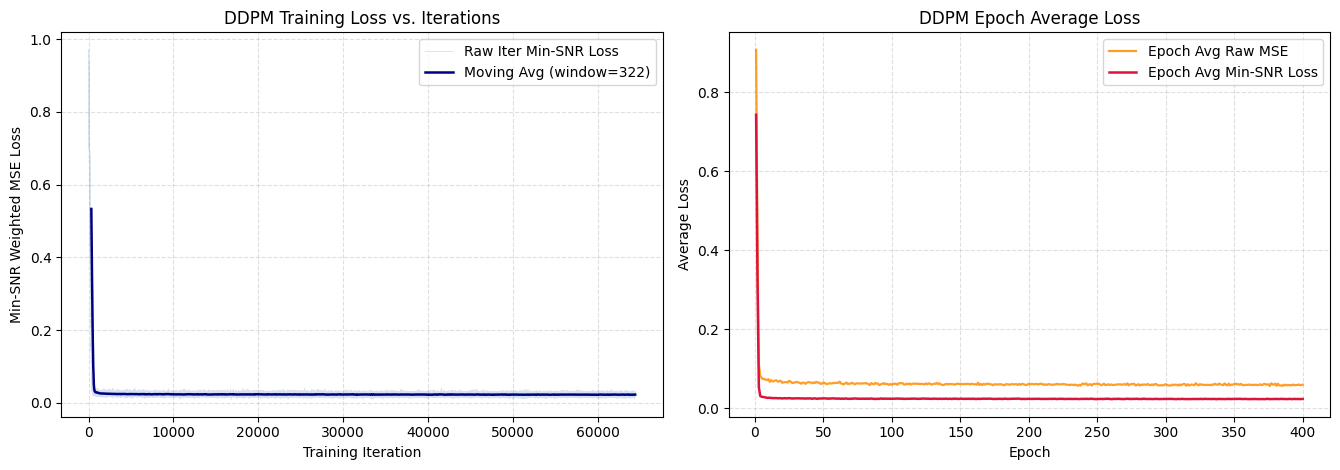

Saved training loss curve to outputs\training_loss_curve.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Left: Iteration-level Min-SNR loss + smoothed curve
steps_arr = np.arange(1, len(step_losses) + 1)
axes[0].plot(steps_arr, step_losses, color="steelblue", alpha=0.22, linewidth=0.6, label="Raw Iter Min-SNR Loss")

if len(step_losses) >= 20:
    window = max(20, len(step_losses) // 200)
    kernel = np.ones(window) / window
    smoothed = np.convolve(step_losses, kernel, mode="valid")
    axes[0].plot(
        np.arange(window, len(step_losses) + 1),
        smoothed,
        color="navy",
        linewidth=1.8,
        label=f"Moving Avg (window={window})",
    )

axes[0].set_title("DDPM Training Loss vs. Iterations")
axes[0].set_xlabel("Training Iteration")
axes[0].set_ylabel("Min-SNR Weighted MSE Loss")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

# Right: Epoch-level average losses
epochs_arr = np.arange(1, len(epoch_losses) + 1)
axes[1].plot(epochs_arr, epoch_raw_mse_losses, color="darkorange", linewidth=1.6, alpha=0.85, label="Epoch Avg Raw MSE")
axes[1].plot(epochs_arr, epoch_losses, color="crimson", linewidth=1.8, label="Epoch Avg Min-SNR Loss")
axes[1].set_title("DDPM Epoch Average Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Average Loss")
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend()

plt.tight_layout()
loss_fig_path = Path(cfg.output_dir) / "training_loss_curve.png"
plt.savefig(loss_fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved training loss curve to {loss_fig_path}")

## 8. Quantitative Evaluation: FID & Inception Score (PyTorch-Ignite)

Following the PyTorch-Ignite evaluation protocol (`https://pytorch-ignite.ai/blog/gan-evaluation-with-fid-and-is/`):
1. Resize both real and generated images from `64 x 64` to `299 x 299` using `PIL.Image.BILINEAR` (via `interpolate()`), mapping `[-1, 1]` tensors to `[0, 1]` prior to `ToPILImage()`.
2. Evaluate `FID(device=device)` and `InceptionScore(device=device, output_transform=lambda x: x[0])` across `eval_num_samples` (`2,048`) real/generated pairs.

In [10]:
# Optional: Load checkpoint if running evaluation standalone
# ckpt = torch.load(Path(cfg.checkpoint_dir) / "ddpm_histopathology_final.pt", map_location=device)
# ema.ema_model.load_state_dict(ckpt["ema_state_dict"])

eval_model = ema.ema_model.to(device).eval()

fid_metric = FID(device=device)
is_metric = InceptionScore(device=device, output_transform=lambda x: x[0])


def interpolate(batch: torch.Tensor) -> torch.Tensor:
    """
    Resize a batch of [-1, 1] tensors to (299, 299) using PIL.Image.BILINEAR,
    consistent with the PyTorch-Ignite FID/IS tutorial.
    """
    arr = []
    for img in batch:
        img_01 = (img.detach().cpu().clamp(-1.0, 1.0) + 1.0) / 2.0
        pil_img = transforms.ToPILImage()(img_01)
        resized_img = pil_img.resize((299, 299), Image.BILINEAR)
        arr.append(transforms.ToTensor()(resized_img))
    return torch.stack(arr)


generated_eval_batches = []
real_eval_batches = []
eval_pbar = tqdm(total=len(eval_dataloader), desc="FID/IS Evaluation Batches")


def evaluation_step(engine, real_batch):
    cur_bs = real_batch.shape[0]
    with torch.no_grad():
        if cfg.eval_use_ddim:
            fake_batch = eval_model.sample_ddim(
                batch_size=cur_bs, ddim_steps=cfg.ddim_steps, eta=cfg.ddim_eta
            )
        else:
            fake_batch = eval_model.sample(batch_size=cur_bs)

    generated_eval_batches.append(fake_batch.cpu())
    real_eval_batches.append(real_batch.cpu())

    fake_299 = interpolate(fake_batch)
    real_299 = interpolate(real_batch)
    eval_pbar.update(1)
    return fake_299, real_299


evaluator = Engine(evaluation_step)
fid_metric.attach(evaluator, "fid")
is_metric.attach(evaluator, "is")

print(f"Running PyTorch-Ignite FID & IS evaluation on {len(eval_dataset)} samples (device={device})...")
eval_start = time.time()
evaluator.run(eval_dataloader, max_epochs=1)
eval_pbar.close()
eval_metrics = evaluator.state.metrics

fid_score_val = float(eval_metrics["fid"])
is_score_val = float(eval_metrics["is"])
eval_elapsed = time.time() - eval_start

print(f"Evaluation completed in {eval_elapsed / 60:.2f} min")
print(f"  * FID Score       : {fid_score_val:.4f} (lower is better)")
print(f"  * Inception Score : {is_score_val:.4f} (higher is better)")

all_fake_images = torch.cat(generated_eval_batches, dim=0)
all_real_images = torch.cat(real_eval_batches, dim=0)

results_summary = {
    "num_eval_samples": len(eval_dataset),
    "sampler": f"DDIM ({cfg.ddim_steps} steps)" if cfg.eval_use_ddim else f"DDPM ({cfg.timesteps} steps)",
    "fid_score": fid_score_val,
    "inception_score": is_score_val,
    "final_epoch_loss": epoch_losses[-1] if epoch_losses else None,
    "best_epoch_loss": min(epoch_losses) if epoch_losses else None,
    "final_epoch_raw_mse": epoch_raw_mse_losses[-1] if epoch_raw_mse_losses else None,
    "best_epoch_raw_mse": min(epoch_raw_mse_losses) if epoch_raw_mse_losses else None,
    "num_parameters": num_params,
}
with open(Path(cfg.output_dir) / "metrics_summary.json", "w") as f:
    json.dump(results_summary, f, indent=2)

FID/IS Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Running PyTorch-Ignite FID & IS evaluation on 2048 samples (device=cuda)...


FID/IS Evaluation Batches: 100%|██████████| 32/32 [33:22<00:00, 62.57s/it]

Evaluation completed in 33.37 min
  * FID Score       : 0.0078 (lower is better)
  * Inception Score : 2.8267 (higher is better)


## 9. Generated Histopathology Images & Denoising Trajectory

We visualize:
1. A side-by-side comparison of **Real Histopathology Images** vs. **DDPM Generated Images** (`outputs/real_vs_generated.png`).
2. A standalone `8 x 8` grid of **Generated Histopathology Images** (`outputs/generated_samples.png`).
3. The progressive reverse diffusion trajectory from pure Gaussian noise ($t=999$) to clean histopathology patches ($t=0$) (`outputs/denoising_trajectory.png`).

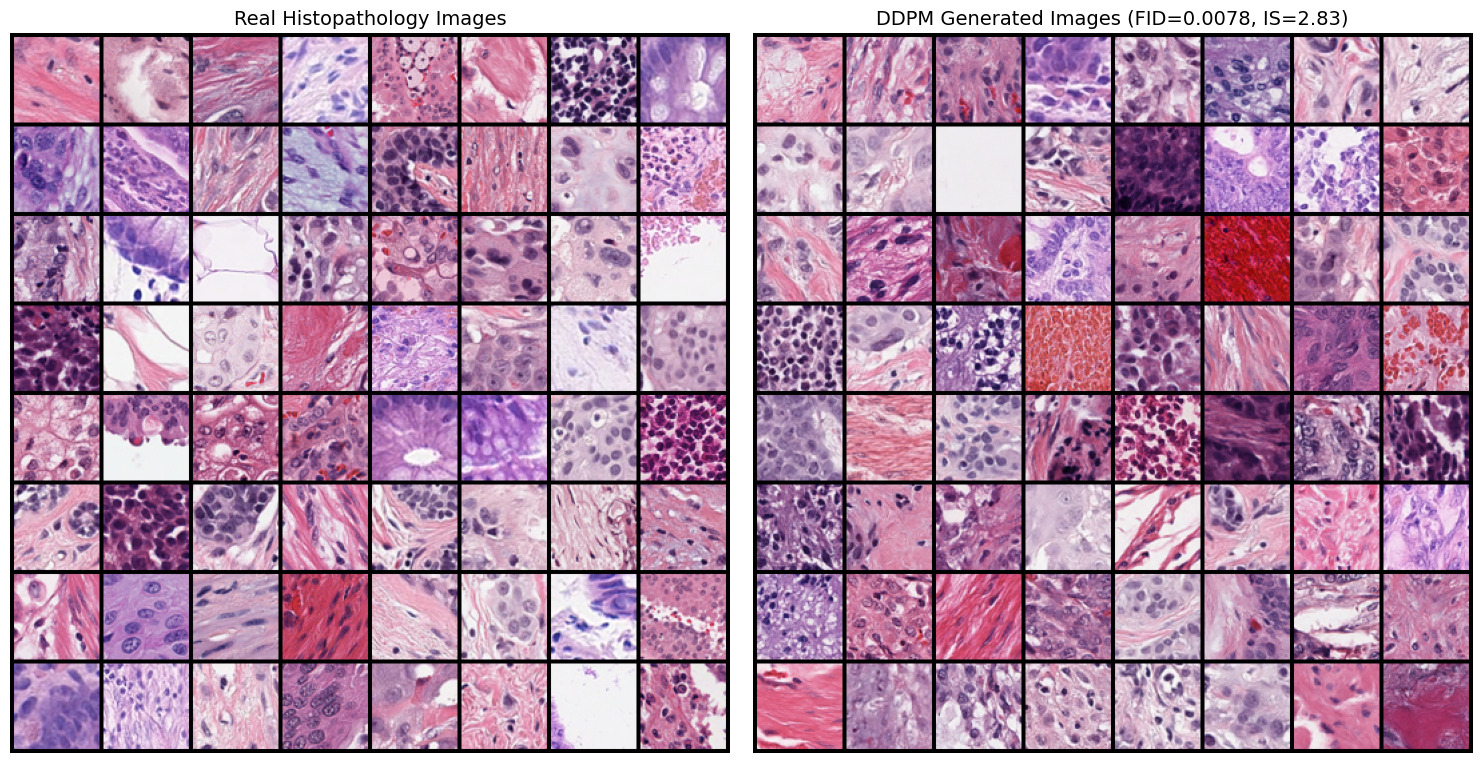

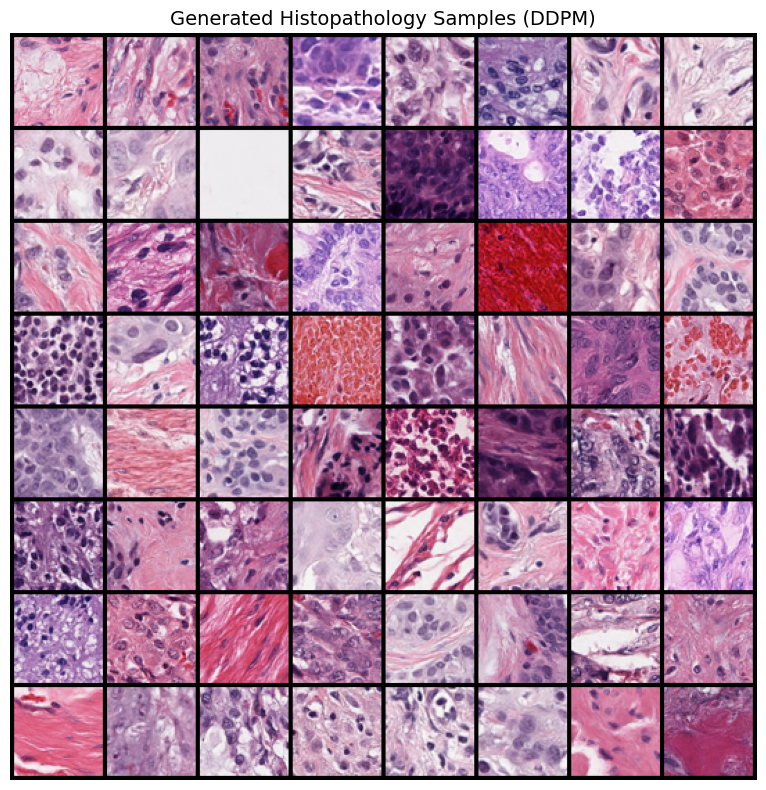

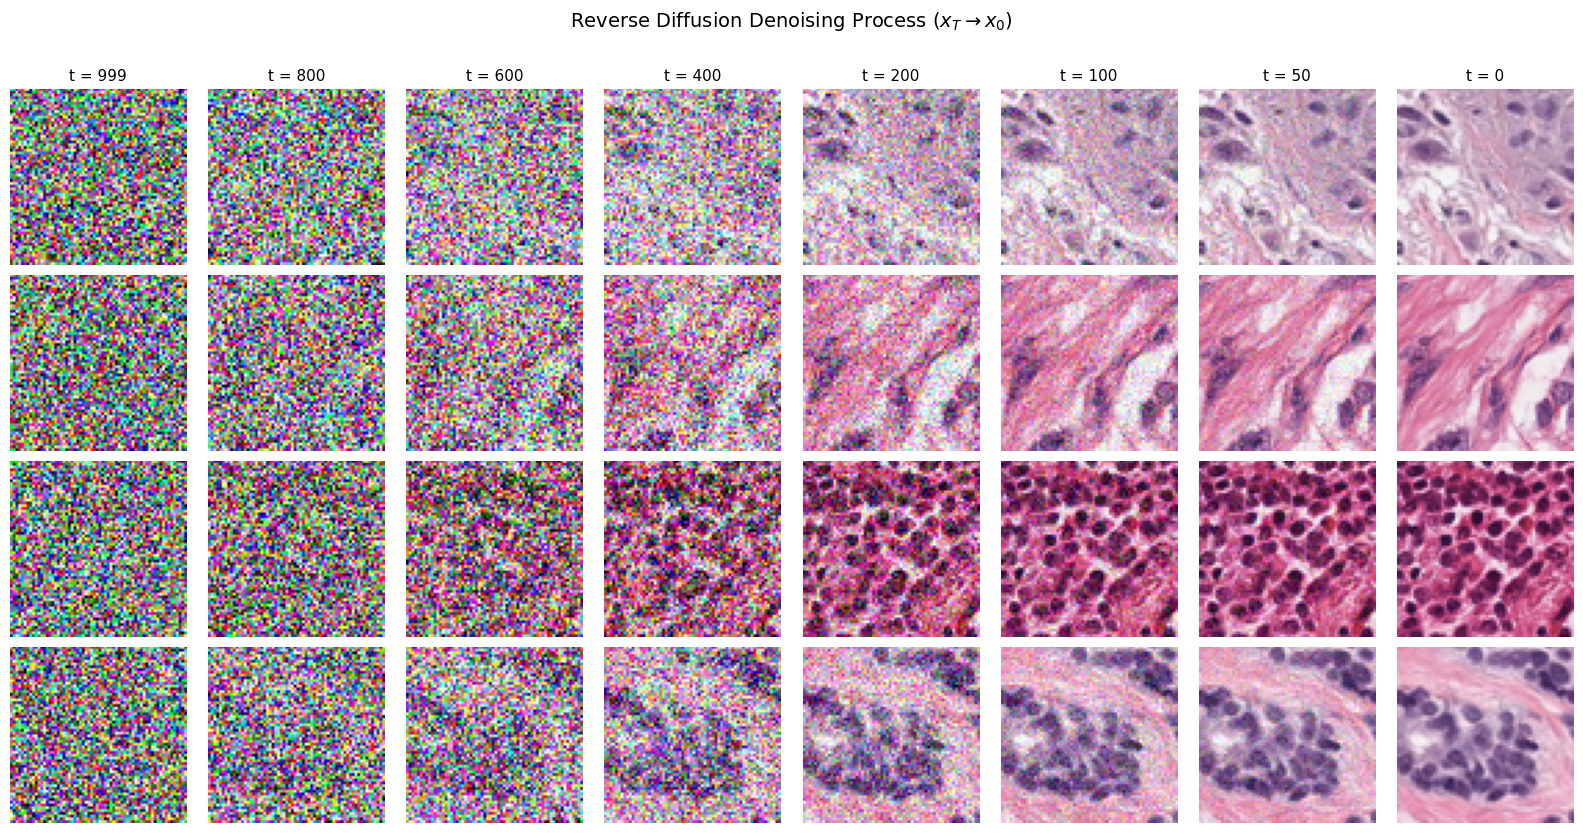

In [11]:
# 1. Real vs. Generated Comparison Grid
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

real_grid = vutils.make_grid(all_real_images[:64], nrow=8, padding=3, normalize=True, value_range=(-1, 1))
fake_grid = vutils.make_grid(all_fake_images[:64], nrow=8, padding=3, normalize=True, value_range=(-1, 1))

axes[0].imshow(np.transpose(real_grid.numpy(), (1, 2, 0)))
axes[0].set_title("Real Histopathology Images", fontsize=14)
axes[0].axis("off")

axes[1].imshow(np.transpose(fake_grid.numpy(), (1, 2, 0)))
axes[1].set_title(f"DDPM Generated Images (FID={fid_score_val:.4f}, IS={is_score_val:.2f})", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
plt.savefig(Path(cfg.output_dir) / "real_vs_generated.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Standalone Generated Samples Grid
plt.figure(figsize=(8, 8))
plt.imshow(np.transpose(fake_grid.numpy(), (1, 2, 0)))
plt.title("Generated Histopathology Samples (DDPM)", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.savefig(Path(cfg.output_dir) / "generated_samples.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Denoising Trajectory Visualization
traj_steps = (999, 800, 600, 400, 200, 100, 50, 0)
with torch.no_grad():
    _, trajectory = eval_model.sample(
        batch_size=4,
        show_progress=True,
        return_trajectory=True,
        trajectory_steps=traj_steps,
    )

fig, axes = plt.subplots(4, len(traj_steps), figsize=(2.0 * len(traj_steps), 8.2))
for col, t_step in enumerate(traj_steps):
    imgs_t = (trajectory[t_step].clamp(-1.0, 1.0) + 1.0) / 2.0
    for row in range(4):
        ax = axes[row, col]
        ax.imshow(np.transpose(imgs_t[row].numpy(), (1, 2, 0)))
        ax.axis("off")
        if row == 0:
            ax.set_title(f"t = {t_step}", fontsize=11)

plt.suptitle(r"Reverse Diffusion Denoising Process ($x_T \rightarrow x_0$)", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(Path(cfg.output_dir) / "denoising_trajectory.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Experiment Summary

In [12]:
print("=" * 65)
print("Experiment Summary")
print("=" * 65)
print(f"Dataset              : Histopathology ({len(train_dataset)} images, resized to {cfg.image_size}x{cfg.image_size})")
print(f"Hardware Accelerator : {device}")
print(f"Model                : AdaGN Time-Conditioned U-Net ({num_params / 1e6:.2f}M params)")
print(f"Diffusion Schedule   : {cfg.beta_schedule}, T={cfg.timesteps}, Min-SNR gamma={cfg.min_snr_gamma}")
print(f"Optimizer            : AdamW (lr={cfg.lr}->{cfg.min_lr}, warmup={cfg.warmup_steps}), EMA={cfg.ema_decay}")
print(f"Batch Size / Epochs  : {cfg.batch_size} / {cfg.epochs} ({global_step:,} total steps)")
if epoch_losses:
    print(f"Final Min-SNR Loss   : {epoch_losses[-1]:.5f} (Best: {min(epoch_losses):.5f})")
    print(f"Final Raw MSE Loss   : {epoch_raw_mse_losses[-1]:.5f} (Best: {min(epoch_raw_mse_losses):.5f})")
print(f"FID Score (Ignite)   : {fid_score_val:.4f}")
print(f"Inception Score      : {is_score_val:.4f}")
print("Saved Artifacts:")
for p in sorted(Path(cfg.output_dir).glob("*")):
    if not p.name.startswith("._"):
        print(f"  - {p}")
print("=" * 65)

Experiment Summary
Dataset              : Histopathology (5179 images, resized to 64x64)
Hardware Accelerator : cuda
Model                : AdaGN Time-Conditioned U-Net (27.66M params)
Diffusion Schedule   : cosine, T=1000, Min-SNR gamma=5.0
Optimizer            : AdamW (lr=0.0002->2e-05, warmup=1000), EMA=0.9995
Batch Size / Epochs  : 32 / 400 (64,400 total steps)
Final Min-SNR Loss   : 0.02294 (Best: 0.02224)
Final Raw MSE Loss   : 0.05932 (Best: 0.05568)
FID Score (Ignite)   : 0.0078
Inception Score      : 2.8267
Saved Artifacts:
  - outputs\denoising_trajectory.png
  - outputs\generated_samples.png
  - outputs\hyperparameters.json
  - outputs\metrics_summary.json
  - outputs\real_samples.png
  - outputs\real_vs_generated.png
  - outputs\samples_epoch_010.png
  - outputs\samples_epoch_020.png
  - outputs\samples_epoch_025.png
  - outputs\samples_epoch_030.png
  - outputs\samples_epoch_040.png
  - outputs\samples_epoch_050.png
  - outputs\samples_epoch_060.png
  - outputs\samples_epo